# 02 · Baseline vs model
A faster, interactive version of `scripts/cv.py`. Leave-one-match-out, with the ball either clean or degraded to look like real automatic tracking.

In [1]:
%load_ext autoreload
%autoreload 2
import sys; sys.path.insert(0, "../src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from possession import data, labels, baseline, features, model, evaluate as ev

In [2]:
names = data.cached_matches()
M = {n: data.load(n) for n in names}
Y = {n: labels.frame_labels(m.frame, m.period, m.events) for n, m in M.items()}
REALISTIC = dict(noise_m=0.7, dropout=0.1, fill_dead=True)   # tweak this
B = {n: ev.degrade_ball(M[n].ball, **REALISTIC, seed=i) for i, n in enumerate(names)}

## Baseline

In [3]:
for n in names:
    print(n, {k: round(v, 3) for k, v in ev.score(Y[n], baseline.predict(M[n], 1.0, 3, ball=B[n])).items()})

sample_game_1 {'acc': 0.706, 'macro_f1': 0.706, 'acc_transitions': 0.549, 'acc_steady': 0.73, 'switches_true': 435, 'switches_pred': 1238}


sample_game_2 {'acc': 0.687, 'macro_f1': 0.688, 'acc_transitions': 0.543, 'acc_steady': 0.708, 'switches_true': 415, 'switches_pred': 1228}


sample_game_3 {'acc': 0.716, 'macro_f1': 0.716, 'acc_transitions': 0.561, 'acc_steady': 0.743, 'switches_true': 451, 'switches_pred': 1345}


## LightGBM + Viterbi (hold out the last match)

In [4]:
test = names[-1]; train = names[:-1]
X = {n: features.build(M[n], B[n]) for n in names}
booster = model.train(pd.concat([X[n] for n in train]), np.concatenate([Y[n] for n in train]))
proba = model.predict_proba(booster, X[test])
pred = model.smooth(proba, M[test].period, switch_penalty=20)
print(ev.score(Y[test], pred)); print(ev.confusion(Y[test], pred))

{'acc': 0.8705699042160252, 'macro_f1': 0.8711280876406037, 'acc_transitions': 0.6942887514495555, 'acc_steady': 0.9002153333604193, 'switches_true': 451, 'switches_pred': 454}
true\pred   none   home   away
     none  0.904  0.064  0.032
     home  0.059  0.868  0.073
     away  0.060  0.095  0.845


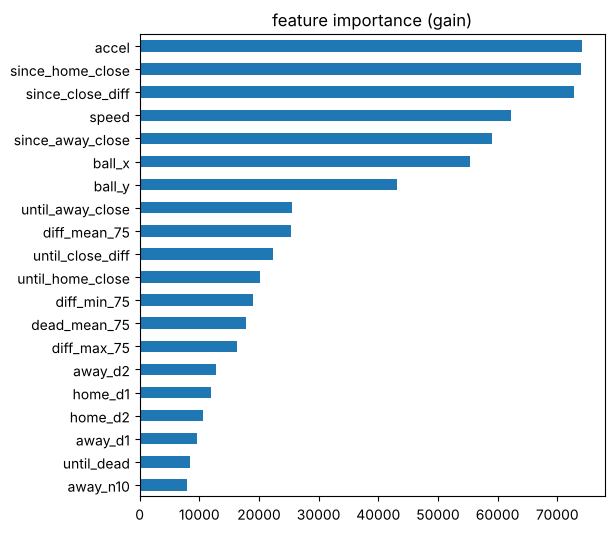

In [5]:
imp = pd.Series(booster.feature_importance("gain"), index=X[test].columns).sort_values()
imp.tail(20).plot.barh(figsize=(6, 6)); plt.title("feature importance (gain)"); plt.show()

## Where does it go wrong?
Truth vs prediction over a window. Change `start` to scroll through the match.

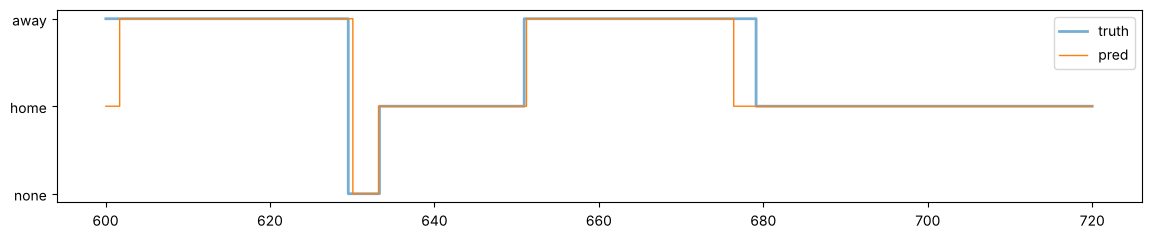

In [6]:
start, secs = 25 * 600, 120
s = slice(start, start + 25 * secs); t = M[test].frame[s] / 25
fig, ax = plt.subplots(figsize=(14, 2.5))
ax.step(t, Y[test][s], where="post", label="truth", lw=2, alpha=.6)
ax.step(t, pred[s], where="post", label="pred", lw=1)
ax.set_yticks([0, 1, 2], labels.CLASS_NAMES); ax.legend(); plt.show()